# TuneTwin AI — Testing Prototype

A student-readable, single-notebook prototype for music features, simulated feedback, recommendations, LinUCB, and optional Spotify playback. **ML TEST MODE works without Spotify credentials.** Dataset columns and Spotify availability are inspected rather than assumed. All user reactions and offline evaluation labels in this notebook are simulated; interpret them as pipeline checks, not real-user evidence.

## 1. Project Setup
**What / why:** Load the analysis libraries, fix random seeds, and define paths and adjustable experiment settings. This keeps repeated notebook runs comparable.

In [1]:
from pathlib import Path
import os, re, warnings, json, ast
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
try:
    from IPython.display import display
except ImportError:
    display = print
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, ndcg_score
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics.pairwise import cosine_similarity
import joblib

SEED = 42
rng = np.random.default_rng(SEED)
DATA_PATH = Path("data/data.csv")  # Kaggle reference notebook uses data.csv; change as needed
MODEL_DIR = Path("models")
MODEL_DIR.mkdir(exist_ok=True)
PCA_VARIANCE_TARGET = 0.90
HYBRID_CONTENT_WEIGHT = 0.5
HYBRID_SUPERVISED_WEIGHT = 0.5
N_SIMULATED_USERS = 5
N_INTERACTIONS_PER_USER = 400
N_EPISODES = 200
LINUCB_ALPHA = 0.7
print("Setup complete. Seed:", SEED, "| Dataset path:", DATA_PATH.resolve())

Setup complete. Seed: 42 | Dataset path: C:\Users\Asmit\Documents\ml_project\data\data.csv


## 2. Dataset Loading
**What / why:** Read the selected CSV. If it is missing, show CSV files under `data/` and stop with an actionable message; no replacement or fabricated data is silently substituted.

In [2]:
# Honor the explicit path first. If it is absent, inspect CSV headers in data/ and select
# a track-level table with the most recognizable audio columns (grouped summary tables score lower).
audio_tokens = ("danceability", "energy", "acousticness", "instrumentalness", "liveness", "loudness", "speechiness", "valence", "tempo", "duration")
if not DATA_PATH.exists():
    csv_paths = list(Path("data").glob("*.csv")) if Path("data").exists() else []
    inspected = []
    for candidate in csv_paths:
        try:
            header = pd.read_csv(candidate, nrows=0).columns.tolist()
            audio_count = sum(any(token in str(c).lower() for token in audio_tokens) for c in header)
            inspected.append((audio_count, candidate, header))
        except Exception as exc:
            print(f"Could not inspect {candidate}: {exc}")
    qualified = [item for item in inspected if item[0] >= 2]
    if qualified:
        qualified.sort(key=lambda item: (item[0], item[1].name.lower() == "data.csv"), reverse=True)
        DATA_PATH = qualified[0][1]
        print("CSV header inspection:", [(str(p), score, cols[:12]) for score, p, cols in inspected])
    else:
        raise FileNotFoundError(
            f"No track-level CSV found. Download the CSV used by the Kaggle reference notebook, "
            f"place it at {Path('data/data.csv').resolve()} (or update DATA_PATH), and rerun. "
            f"CSV files inspected: {[str(p) for p in csv_paths]}"
        )
tracks_raw = pd.read_csv(DATA_PATH, low_memory=False)
print(f"Loaded {len(tracks_raw):,} rows × {tracks_raw.shape[1]} columns from {DATA_PATH}")

Loaded 170,653 rows × 19 columns from data\data.csv


## 3. Dataset Inspection
**What / why:** Inspect the actual schema and identify likely metadata and numerical audio features. We do not invent absent columns.

In [3]:
print("Shape:", tracks_raw.shape)
display(pd.DataFrame({"dtype": tracks_raw.dtypes.astype(str), "missing": tracks_raw.isna().sum(), "unique": tracks_raw.nunique(dropna=True)}))
print("Exact duplicate rows:", int(tracks_raw.duplicated().sum()))
display(tracks_raw.head())
print("Columns:", tracks_raw.columns.tolist())

Shape: (170653, 19)


,dtype,missing,unique
valence,float64,0,1733
year,int64,0,100
acousticness,float64,0,4689
artists,object,0,34088
danceability,float64,0,1240
duration_ms,int64,0,51755
energy,float64,0,2332
explicit,int64,0,2
id,object,0,170653
instrumentalness,float64,0,5401


Exact duplicate rows: 0


,valence,year,acousticness,artists,danceability,duration_ms,energy,explicit,id,instrumentalness,key,liveness,loudness,mode,name,popularity,release_date,speechiness,tempo
0,0.0594,1921,0.982,"['Sergei Rachmaninoff', 'James Levine', 'Berli...",0.279,831667,0.211,0,4BJqT0PrAfrxzMOxytFOIz,0.878000,10,0.665,-20.096,1,"Piano Concerto No. 3 in D Minor, Op. 30: III. ...",4,1921,0.0366,80.954
1,0.9630,1921,0.732,['Dennis Day'],0.819,180533,0.341,0,7xPhfUan2yNtyFG0cUWkt8,0.000000,7,0.160,-12.441,1,Clancy Lowered the Boom,5,1921,0.4150,60.936
2,0.0394,1921,0.961,['KHP Kridhamardawa Karaton Ngayogyakarta Hadi...,0.328,500062,0.166,0,1o6I8BglA6ylDMrIELygv1,0.913000,3,0.101,-14.850,1,Gati Bali,5,1921,0.0339,110.339
3,0.1650,1921,0.967,['Frank Parker'],0.275,210000,0.309,0,3ftBPsC5vPBKxYSee08FDH,0.000028,5,0.381,-9.316,1,Danny Boy,3,1921,0.0354,100.109
4,0.2530,1921,0.957,['Phil Regan'],0.418,166693,0.193,0,4d6HGyGT8e121BsdKmw9v6,0.000002,3,0.229,-10.096,1,When Irish Eyes Are Smiling,2,1921,0.0380,101.665


Columns: ['valence', 'year', 'acousticness', 'artists', 'danceability', 'duration_ms', 'energy', 'explicit', 'id', 'instrumentalness', 'key', 'liveness', 'loudness', 'mode', 'name', 'popularity', 'release_date', 'speechiness', 'tempo']


## 4. EDA
**What / why:** Summarize numeric distributions, available genre and popularity fields, and correlations. These charts describe this CSV only.

Tracks: 170653 | columns: 19 | numeric columns: 15


,count,mean,std,min,25%,50%,75%,max
valence,170653.0,0.528587,0.263171,0.0,0.3170,0.540000,0.7470,1.000
year,170653.0,1976.787241,25.917853,1921.0,1956.0000,1977.000000,1999.0000,2020.000
acousticness,170653.0,0.502115,0.376032,0.0,0.1020,0.516000,0.8930,0.996
danceability,170653.0,0.537396,0.176138,0.0,0.4150,0.548000,0.6680,0.988
duration_ms,170653.0,230948.310666,126118.414668,5108.0,169827.0000,207467.000000,262400.0000,5403500.000
energy,170653.0,0.482389,0.267646,0.0,0.2550,0.471000,0.7030,1.000
explicit,170653.0,0.084575,0.278249,0.0,0.0000,0.000000,0.0000,1.000
instrumentalness,170653.0,0.167010,0.313475,0.0,0.0000,0.000216,0.1020,1.000
key,170653.0,5.199844,3.515094,0.0,2.0000,5.000000,8.0000,11.000
liveness,170653.0,0.205839,0.174805,0.0,0.0988,0.136000,0.2610,1.000


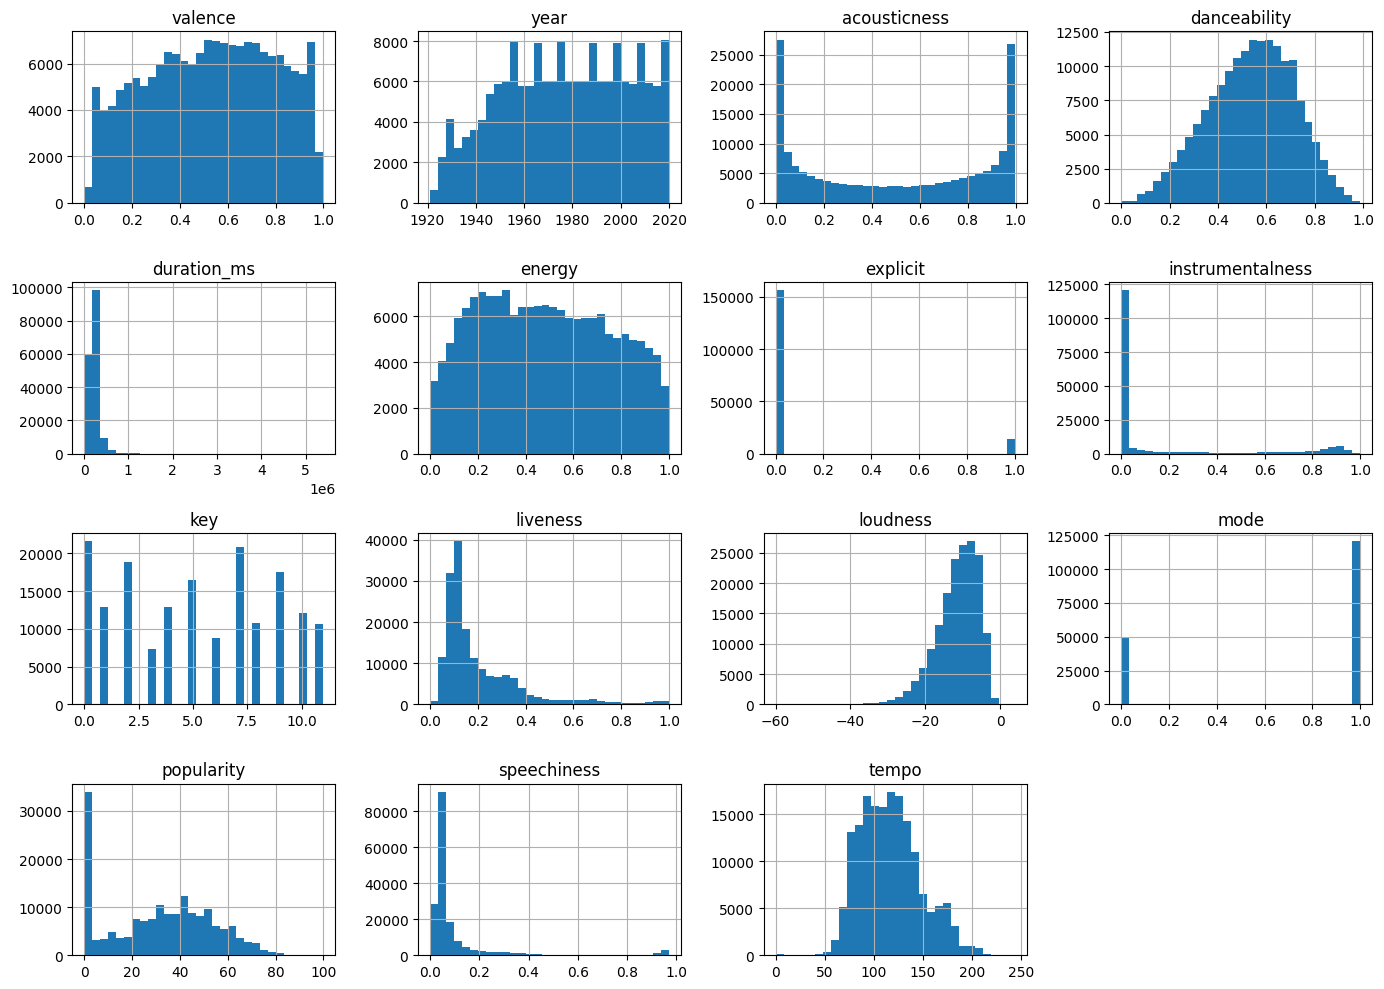

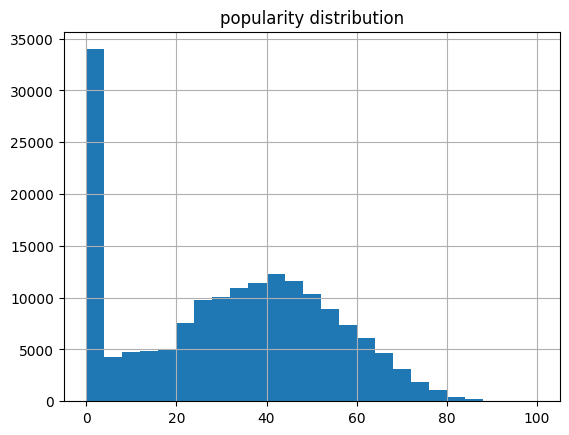

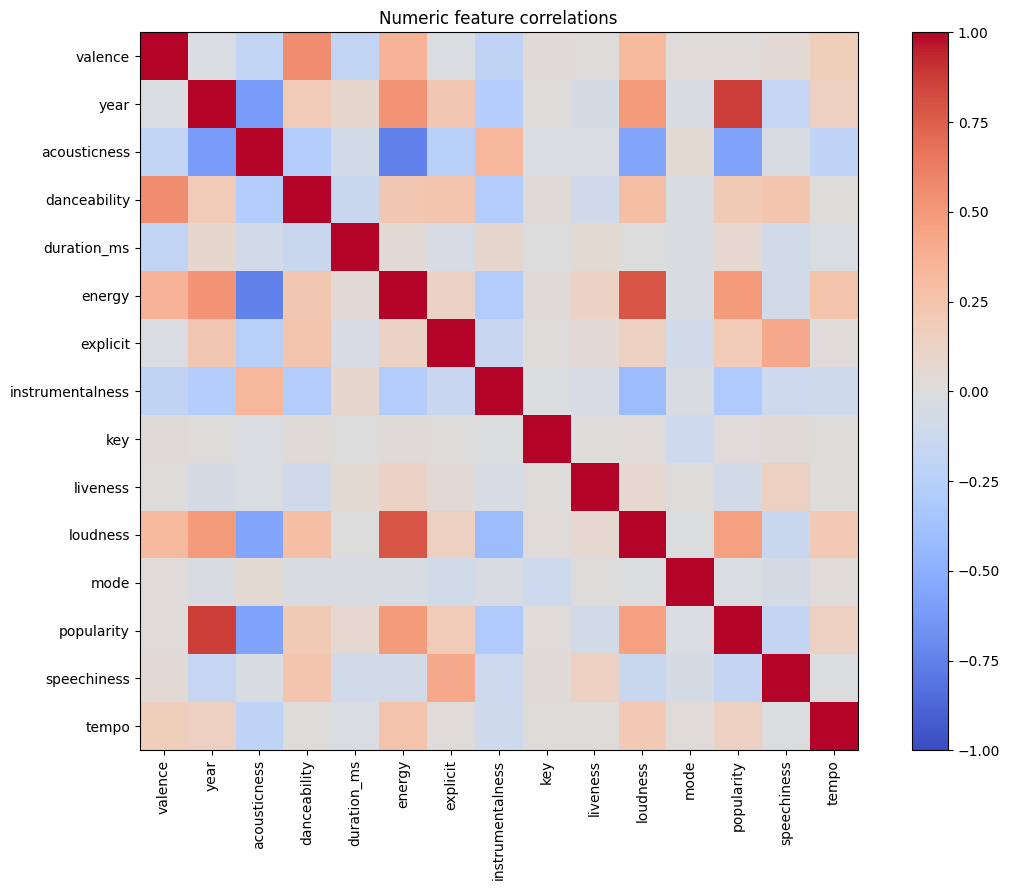

In [4]:
numeric_raw = tracks_raw.select_dtypes(include=np.number)
print("Tracks:", len(tracks_raw), "| columns:", tracks_raw.shape[1], "| numeric columns:", len(numeric_raw.columns))
display(numeric_raw.describe().T)
if len(numeric_raw.columns):
    numeric_raw.hist(figsize=(14, 10), bins=30); plt.tight_layout(); plt.show()
lower_cols = {str(c).lower(): c for c in tracks_raw.columns}
pop_col = next((lower_cols[k] for k in ["popularity"] if k in lower_cols), None)
genre_col = next((c for c in tracks_raw.columns if "genre" in str(c).lower()), None)
if pop_col:
    tracks_raw[pop_col].dropna().hist(bins=25); plt.title(f"{pop_col} distribution"); plt.show()
if genre_col:
    display(tracks_raw[genre_col].value_counts().head(20).rename("tracks").to_frame())
if len(numeric_raw.columns) > 1:
    corr = numeric_raw.corr()
    plt.figure(figsize=(12, 9)); plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1); plt.colorbar(); plt.xticks(range(len(corr)), corr.columns, rotation=90); plt.yticks(range(len(corr)), corr.columns); plt.title("Numeric feature correlations"); plt.tight_layout(); plt.show()

## 5. Data Preprocessing
**What / why:** Remove exact duplicate rows, coerce potential audio features to numeric, and keep descriptive metadata separate. A missing expected field simply stays unavailable.

In [5]:
tracks = tracks_raw.drop_duplicates().copy().reset_index(drop=True)
track_id_col = next((c for c in tracks.columns if str(c).strip().lower() in {"id", "track_id", "spotify_id"}), None)
if track_id_col:
    has_id = tracks[track_id_col].notna()
    duplicate_id_count = int(tracks.loc[has_id, track_id_col].duplicated().sum())
    tracks = pd.concat([tracks.loc[has_id].drop_duplicates(subset=[track_id_col], keep="first"), tracks.loc[~has_id]], ignore_index=True)
    print(f"Removed {duplicate_id_count} repeated track identifiers using {track_id_col!r}")
else:
    print("No recognized track identifier column; exact duplicate rows were removed only.")
metadata_tokens = ("id", "name", "artist", "album", "genre", "uri", "url", "type", "key", "mode")
preferred_tokens = ("danceability", "energy", "acousticness", "instrumentalness", "liveness", "loudness", "speechiness", "valence", "tempo", "duration")
feature_candidates = [c for c in tracks.columns if any(t in str(c).lower() for t in preferred_tokens)]
feature_candidates = [c for c in feature_candidates if not any(t in str(c).lower() for t in ("id", "name", "artist", "album", "genre"))]
for c in feature_candidates:
    tracks[c] = pd.to_numeric(tracks[c], errors="coerce")
feature_candidates = [c for c in feature_candidates if tracks[c].notna().sum() > 1 and tracks[c].nunique(dropna=True) > 1]
if len(feature_candidates) < 2:
    raise ValueError(f"Need at least 2 usable numeric audio feature columns; found {feature_candidates}. Inspect columns and update feature_candidates.")
metadata_cols = [c for c in tracks.columns if c not in feature_candidates]
metadata = tracks[metadata_cols].copy()
print("Candidate audio features actually found:", feature_candidates)
print("Metadata columns:", metadata_cols)
print("Rows after exact-duplicate removal:", len(tracks))

Removed 0 repeated track identifiers using 'id'
Candidate audio features actually found: ['valence', 'acousticness', 'danceability', 'duration_ms', 'energy', 'instrumentalness', 'liveness', 'loudness', 'speechiness', 'tempo']
Metadata columns: ['year', 'artists', 'explicit', 'id', 'key', 'mode', 'name', 'popularity', 'release_date']
Rows after exact-duplicate removal: 170653


## 6. Feature Engineering
**What / why:** Use only audio-like numeric columns present in the file. Drop columns with no numeric data, impute remaining missing values by median, cap extreme tails using training-independent 1st/99th percentiles, then standardize. Identifiers never enter the model.

In [6]:
feature_frame = tracks[feature_candidates].replace([np.inf, -np.inf], np.nan)
usable = feature_frame.notna().sum() >= 2
feature_frame = feature_frame.loc[:, usable]
FEATURES = feature_frame.columns.tolist()
if len(FEATURES) < 2: raise ValueError("Fewer than two usable features remain after invalid-value cleaning.")
lower = feature_frame.quantile(0.01); upper = feature_frame.quantile(0.99)
feature_frame = feature_frame.clip(lower=lower, upper=upper, axis="columns")
imputer = SimpleImputer(strategy="median")
X_imputed = imputer.fit_transform(feature_frame)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputed)
print("Final feature list:", FEATURES, "| matrix:", X_scaled.shape)
print("Rows with any originally missing feature:", int(feature_frame.isna().any(axis=1).sum()))

Final feature list: ['valence', 'acousticness', 'danceability', 'duration_ms', 'energy', 'instrumentalness', 'liveness', 'loudness', 'speechiness', 'tempo'] | matrix: (170653, 10)
Rows with any originally missing feature: 0


## 7. PCA
**What / why:** PCA rotates the standardized feature space into components that retain as much variance as possible. We select the component count that reaches the configured cumulative variance target and also make a 2D view where possible.

,component,explained_variance,cumulative
0,1,0.308701,0.308701
1,2,0.154722,0.463424
2,3,0.113922,0.577346
3,4,0.098441,0.675787
4,5,0.087730,0.763517
5,6,0.083387,0.846904
6,7,0.068308,0.915212
7,8,0.037763,0.952976
8,9,0.035099,0.988075
9,10,0.011925,1.000000


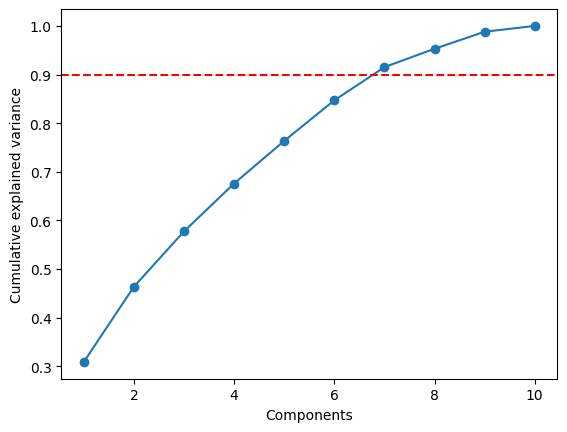

Selected 7 components; retained variance=0.915


In [7]:
pca_full = PCA(random_state=SEED).fit(X_scaled)
cumulative = np.cumsum(pca_full.explained_variance_ratio_)
n_components = int(np.searchsorted(cumulative, PCA_VARIANCE_TARGET) + 1)
pca = PCA(n_components=n_components, random_state=SEED)
X_pca = pca.fit_transform(X_scaled)
pca_2d = PCA(n_components=2, random_state=SEED).fit_transform(X_scaled)
display(pd.DataFrame({"component": np.arange(1, len(cumulative)+1), "explained_variance": pca_full.explained_variance_ratio_, "cumulative": cumulative}))
plt.plot(np.arange(1, len(cumulative)+1), cumulative, marker="o"); plt.axhline(PCA_VARIANCE_TARGET, color="red", linestyle="--"); plt.xlabel("Components"); plt.ylabel("Cumulative explained variance"); plt.show()
print(f"Selected {n_components} components; retained variance={pca.explained_variance_ratio_.sum():.3f}")

## 8. K-Means Clustering
**What / why:** Compare K values using inertia and silhouette score on a bounded sample for speed. Select the tested K with the highest measured silhouette; cluster labels are numeric and have no assumed mood meaning.

,k,inertia,silhouette
0,2,20752.182815,0.239954
1,3,18489.943206,0.190826
2,4,15975.211442,0.222028
3,5,14558.220057,0.184722
4,6,13384.468108,0.189047
5,7,12352.414939,0.180970
6,8,11538.122863,0.188245
7,9,10905.766514,0.188127
8,10,10300.026149,0.186676


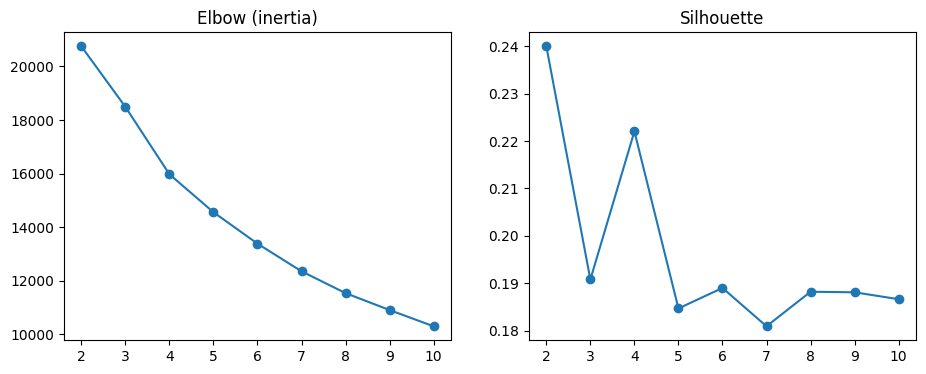

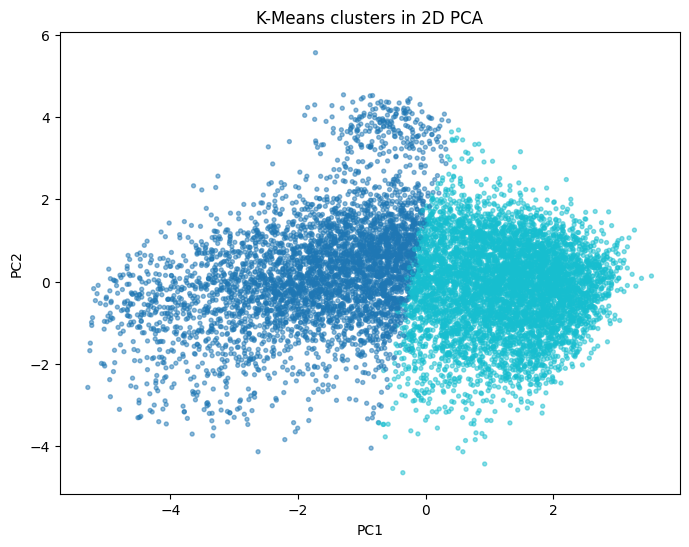

Tested K: [2, 3, 4, 5, 6, 7, 8, 9, 10] | selected: 2 | measured silhouette: 0.2399535851987439


In [8]:
n_rows = len(X_pca)
if n_rows < 3: raise ValueError("Need at least 3 usable tracks for clustering.")
cluster_space = X_pca if X_pca.shape[1] <= 15 else X_pca[:, :15]
max_k = min(10, n_rows - 1)
K_VALUES = list(range(2, max_k + 1))
cluster_sample_idx = rng.choice(n_rows, min(n_rows, 3000), replace=False)
sample_cluster_space = cluster_space[cluster_sample_idx]
cluster_rows = []
for k in K_VALUES:
    km = KMeans(n_clusters=k, random_state=SEED, n_init=10).fit(sample_cluster_space)
    sil = silhouette_score(sample_cluster_space, km.labels_) if len(cluster_sample_idx) > k else np.nan
    cluster_rows.append({"k": k, "inertia": km.inertia_, "silhouette": sil})
cluster_results = pd.DataFrame(cluster_rows)
display(cluster_results)
fig, ax = plt.subplots(1,2, figsize=(11,4)); ax[0].plot(cluster_results.k, cluster_results.inertia, marker="o"); ax[0].set_title("Elbow (inertia)"); ax[1].plot(cluster_results.k, cluster_results.silhouette, marker="o"); ax[1].set_title("Silhouette"); plt.show()
selected_k = int(cluster_results.loc[cluster_results.silhouette.idxmax(), "k"])
kmeans = KMeans(n_clusters=selected_k, random_state=SEED, n_init=10).fit(cluster_space)
cluster_labels = kmeans.labels_
plot_idx = rng.choice(n_rows, min(n_rows, 10000), replace=False)
plt.figure(figsize=(8,6)); plt.scatter(pca_2d[plot_idx,0], pca_2d[plot_idx,1], c=cluster_labels[plot_idx], s=8, alpha=.5, cmap="tab10"); plt.title("K-Means clusters in 2D PCA"); plt.xlabel("PC1"); plt.ylabel("PC2"); plt.show()
print("Tested K:", K_VALUES, "| selected:", selected_k, "| measured silhouette:", float(cluster_results.loc[cluster_results.k==selected_k, "silhouette"].iloc[0]))

## 9. Simulated User Profiles
**What / why:** Construct several preference vectors from empirical feature quantiles, so varied feature scales and dataset schema are respected. Profiles drive probabilistic feedback only; they do not directly assign recommendations.

In [9]:
# Convert catalog feature values to a common 0..1 range for profile similarity.
feature_min = np.nanmin(X_imputed, axis=0); feature_max = np.nanmax(X_imputed, axis=0)
X_unit = np.clip((X_imputed - feature_min) / np.where(feature_max > feature_min, feature_max-feature_min, 1), 0, 1)
# Preference targets only shape probabilistic simulated feedback; recommenders learn/rank separately.
profile_specs = [
    {"energy": .85, "danceability": .85},
    {"acousticness": .85, "energy": .20},
    {"instrumentalness": .95},
    {"valence": .90},
    {"energy": .65, "valence": .70, "danceability": .60, "acousticness": .45},
]
preference_profiles = {}
median_profile = np.median(X_unit, axis=0)
for user_i in range(N_SIMULATED_USERS):
    profile = median_profile.copy()
    for feature_name, target_value in profile_specs[user_i % len(profile_specs)].items():
        if feature_name in FEATURES:
            profile[FEATURES.index(feature_name)] = target_value
    preference_profiles[f"user_{user_i+1}"] = profile
profiles_df = pd.DataFrame(preference_profiles, index=FEATURES).T
display(profiles_df.round(2))

,valence,acousticness,danceability,duration_ms,energy,instrumentalness,liveness,loudness,speechiness,tempo
user_1,0.54,0.52,0.85,0.24,0.85,0.00,0.11,0.7,0.02,0.39
user_2,0.54,0.85,0.55,0.24,0.20,0.00,0.11,0.7,0.02,0.39
user_3,0.54,0.52,0.55,0.24,0.47,0.95,0.11,0.7,0.02,0.39
user_4,0.90,0.52,0.55,0.24,0.47,0.00,0.11,0.7,0.02,0.39
user_5,0.70,0.45,0.60,0.24,0.65,0.00,0.11,0.7,0.02,0.39


## 10. Supervised Learning — Simulated User Interaction Data
**What / why:** Generate noisy like/dislike labels from preference-to-track similarity and a probabilistic feedback process. Train five candidate classifiers with a track-grouped train/test split to avoid the same tracks appearing in both sets. Results describe this simulator, not real listeners.

In [10]:
# Simulate interactions with a noisy preference score; target is liked/not liked.
interaction_parts = []
sample_n = min(len(tracks), max(30, N_INTERACTIONS_PER_USER))
for user_id, pref in preference_profiles.items():
    chosen = rng.choice(len(tracks), size=sample_n, replace=(sample_n > len(tracks)))
    distances = np.linalg.norm(X_unit[chosen] - pref, axis=1) / np.sqrt(len(FEATURES))
    p_like = np.clip(1 / (1 + np.exp(-8 * (0.42-distances))), .05, .95)
    liked = rng.binomial(1, p_like)
    part = pd.DataFrame(X_scaled[chosen], columns=FEATURES)
    pref_values = (pref * (feature_max-feature_min) + feature_min - scaler.mean_) / scaler.scale_
    pref_columns = [f"user_pref__{c}" for c in FEATURES]
    for column, value in zip(pref_columns, pref_values): part[column] = value
    part["user_id"] = user_id; part["track_row"] = chosen; part["liked"] = liked
    interaction_parts.append(part)
interactions = pd.concat(interaction_parts, ignore_index=True)
print("Simulated interactions:", interactions.shape, "| overall like rate:", interactions.liked.mean().round(3))
PREF_FEATURES = [f"user_pref__{c}" for c in FEATURES]
MODEL_FEATURES = FEATURES + PREF_FEATURES
X_inter = interactions[MODEL_FEATURES]; y_inter = interactions.liked
groups = interactions.track_row
splitter = GroupShuffleSplit(n_splits=1, test_size=.25, random_state=SEED)
train_idx, test_idx = next(splitter.split(X_inter, y_inter, groups))
if y_inter.iloc[train_idx].nunique() < 2 or y_inter.iloc[test_idx].nunique() < 2:
    raise ValueError("Simulated grouped split has only one target class; increase available tracks/interactions.")
models = {
    "Logistic Regression": make_pipeline(SimpleImputer(strategy="median"), LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED)),
    "KNN": make_pipeline(SimpleImputer(strategy="median"), KNeighborsClassifier(n_neighbors=7)),
    "Decision Tree": make_pipeline(SimpleImputer(strategy="median"), DecisionTreeClassifier(max_depth=8, class_weight="balanced", random_state=SEED)),
    "Random Forest": make_pipeline(SimpleImputer(strategy="median"), RandomForestClassifier(n_estimators=150, max_depth=12, class_weight="balanced", random_state=SEED, n_jobs=-1)),
    "Gradient Boosting": make_pipeline(SimpleImputer(strategy="median"), GradientBoostingClassifier(random_state=SEED))
}
metric_rows = []
for name, model in models.items():
    model.fit(X_inter.iloc[train_idx], y_inter.iloc[train_idx]); pred = model.predict(X_inter.iloc[test_idx]); prob = model.predict_proba(X_inter.iloc[test_idx])[:,1]
    metric_rows.append({"model":name,"accuracy":accuracy_score(y_inter.iloc[test_idx],pred),"precision":precision_score(y_inter.iloc[test_idx],pred,zero_division=0),"recall":recall_score(y_inter.iloc[test_idx],pred,zero_division=0),"f1":f1_score(y_inter.iloc[test_idx],pred,zero_division=0),"roc_auc":roc_auc_score(y_inter.iloc[test_idx],prob)})
model_metrics = pd.DataFrame(metric_rows).sort_values("f1", ascending=False).reset_index(drop=True)
display(model_metrics)
best_model_name = model_metrics.iloc[0].model
best_model = models[best_model_name]
best_model.fit(X_inter, y_inter)
print("Selected by held-out F1:", best_model_name)

Simulated interactions: (2000, 23) | overall like rate: 0.713


,model,accuracy,precision,recall,f1,roc_auc
0,Gradient Boosting,0.713147,0.727273,0.939828,0.820000,0.624548
1,KNN,0.685259,0.717540,0.902579,0.799492,0.641600
2,Random Forest,0.657371,0.738544,0.785100,0.761111,0.619623
3,Logistic Regression,0.663347,0.783019,0.713467,0.746627,0.660973
4,Decision Tree,0.631474,0.725275,0.756447,0.740533,0.500478


Selected by held-out F1: Gradient Boosting


## 11. Content-Based Recommendation
**What / why:** Rank tracks by cosine similarity to a seed track or a simulated user preference vector. Similarity uses standardized features, and a seed track is excluded from its own results.

In [11]:
def metadata_column(tokens):
    normalized = {re.sub(r"[^a-z0-9]", "", str(c).lower()): c for c in metadata.columns}
    for token in tokens:
        key = re.sub(r"[^a-z0-9]", "", token.lower())
        if key in normalized: return normalized[key]
    return next((c for c in metadata.columns if any(t in str(c).lower() for t in tokens)), None)
TRACK_NAME_COL = metadata_column(["track_name", "track title", "track", "title", "name"])
ARTIST_COL = metadata_column(["artist_name", "artists", "artist"]); TRACK_ID_COL = metadata_column(["track_id", "spotify_id", "track id", "id"]); GENRE_COL = metadata_column(["genre"])
def track_display(rows):
    out = metadata.iloc[rows].copy()
    out["similarity"] = np.nan
    return out
def recommend_content(user_id=None, seed_idx=None, n=10, exclude_rows=None):
    if seed_idx is not None:
        query = X_scaled[seed_idx].reshape(1,-1); exclude = {seed_idx}
    elif user_id is not None:
        pref = preference_profiles[user_id]
        pref_scaled = (pref * (feature_max-feature_min) + feature_min - scaler.mean_) / scaler.scale_
        query = pref_scaled.reshape(1,-1); exclude = set()
    else: raise ValueError("Provide user_id or seed_idx")
    exclude |= set(exclude_rows or [])
    sims = cosine_similarity(query, X_scaled).ravel()
    if exclude: sims[list(exclude)] = -np.inf
    idx = np.argsort(sims)[::-1][:n]
    result = metadata.iloc[idx].copy(); result["similarity"] = sims[idx]
    return result
display(recommend_content(user_id=list(preference_profiles)[0], n=5))

,year,artists,explicit,id,key,mode,name,popularity,release_date,similarity
12894,1986,['Janet Jackson'],0,07OzC5JlcaDwEkzWmvqp6y,1,0,Nasty,53,1986-02-04,0.959620
161804,1976,['Roy Ayers Ubiquity'],0,1YvpR7DP7NXrof6DHfM8OG,9,0,You And Me My Love,25,1976-05-12,0.952803
112948,1960,['Babatunde Olatunji'],0,5swc6TamJpZwKMQmCMtW7k,0,1,Jin-Go-Lo-Ba (Jin-Go-Low-Bah),10,1960,0.936278
148909,1986,['Princess'],0,1SlaWDU54ToxvNsMeG5fsL,6,0,Say I'm Your No. 1,40,1986-01-01,0.931051
151897,2001,['DMX'],1,5IaBQjc8iZYsrleSQHBHxH,4,0,Damien III,41,2001-01-01,0.923780


### Genre- and Artist-Aware Seed Recommendations

The track-level `data.csv` does not contain track genres. The Kaggle archive also supplies `data_w_genres.csv`, which maps artists to genre tags. When that file is available, this cell joins genres to each track through its artist metadata. For a seed song, the recommender ranks other tracks using configurable audio-feature similarity, genre overlap, and a same-artist bonus. The example weights are adjustable experiments, not optimized values. A configurable cap prevents the seed artist from taking over the list (default: at most one track per artist). If the seed has genre tags, candidates with missing tags receive zero for the genre component rather than bypassing that weight. This uses metadata lookup, not text tokenization.

In [12]:
def parse_list_field(value):
    if pd.isna(value): return []
    if isinstance(value, (list, tuple, set)): return [str(x).strip() for x in value if str(x).strip()]
    text = str(value).strip()
    try:
        parsed = ast.literal_eval(text)
        if isinstance(parsed, (list, tuple, set)): return [str(x).strip() for x in parsed if str(x).strip()]
        if isinstance(parsed, str): return [parsed.strip()] if parsed.strip() else []
    except (ValueError, SyntaxError):
        pass
    return [text] if text else []

genre_file = next(iter(Path("data").rglob("data_w_genres.csv")), None)
artist_genres = {}
if genre_file is not None:
    genre_table = pd.read_csv(genre_file, low_memory=False)
    genre_artist_col = next((c for c in genre_table.columns if str(c).strip().lower() in {"artist", "artists"}), None)
    genre_tags_col = next((c for c in genre_table.columns if "genre" in str(c).lower()), None)
    if genre_artist_col and genre_tags_col:
        for _, row in genre_table[[genre_artist_col, genre_tags_col]].dropna(subset=[genre_artist_col]).iterrows():
            for artist_name in parse_list_field(row[genre_artist_col]):
                key = artist_name.casefold().strip()
                artist_genres.setdefault(key, set()).update(g.casefold().strip() for g in parse_list_field(row[genre_tags_col]) if g.strip())
    print("Artist genre mapping file:", genre_file, "| artists mapped:", len(artist_genres))
else:
    print("No data_w_genres.csv found; genre scoring will be unavailable unless the track table has genre labels.")

track_artists = [parse_list_field(v) for v in metadata[ARTIST_COL]] if ARTIST_COL else [[] for _ in range(len(metadata))]
track_artist_sets = [{a.casefold().strip() for a in artists} for artists in track_artists]
track_genres = []
for row_idx, artists in enumerate(track_artists):
    tags = set()
    for artist_name in artists:
        tags.update(artist_genres.get(artist_name.casefold().strip(), set()))
    if not tags and GENRE_COL:
        tags.update(g.casefold().strip() for g in parse_list_field(metadata.iloc[row_idx][GENRE_COL]))
    track_genres.append(tags)
metadata["genres"] = [", ".join(sorted(tags)) if tags else "Unknown" for tags in track_genres]
genre_coverage = float(np.mean([bool(x) for x in track_genres]))
print(f"Tracks with at least one genre tag: {genre_coverage:.1%}")

SONG_SIMILARITY_WEIGHTS = {"audio": 0.60, "genre": 0.25, "same_artist": 0.15}
def find_track_row(track_name, artist_name=None):
    if TRACK_NAME_COL is None: raise ValueError("This dataset has no recognized track-name column.")
    names = metadata[TRACK_NAME_COL].astype(str).str.casefold().str.strip()
    matches = metadata.index[names == str(track_name).casefold().strip()].tolist()
    if artist_name and ARTIST_COL:
        matches = [i for i in matches if str(artist_name).casefold().strip() in metadata.iloc[i][ARTIST_COL].casefold()]
    if not matches: raise ValueError(f"No catalog match for track={track_name!r}, artist={artist_name!r}.")
    if len(matches) > 1: print(f"Found {len(matches)} matches; using the first. Add an artist name to disambiguate.")
    return int(matches[0])

def recommend_similar_tracks(seed_idx, n=5, weights=None, max_per_artist=1):
    weights = dict(SONG_SIMILARITY_WEIGHTS if weights is None else weights)
    if set(weights) != {"audio", "genre", "same_artist"} or any(v < 0 for v in weights.values()) or sum(weights.values()) <= 0:
        raise ValueError("weights must provide nonnegative audio, genre, and same_artist values with positive total.")
    if max_per_artist is not None and (not isinstance(max_per_artist, int) or max_per_artist < 1):
        raise ValueError("max_per_artist must be a positive integer or None.")
    audio = (cosine_similarity(X_scaled[seed_idx:seed_idx+1], X_scaled).ravel() + 1) / 2
    seed_genres = track_genres[seed_idx]
    seed_artists = track_artist_sets[seed_idx]
    ranked_rows=[]; component_rows=[]
    for row_idx in range(len(metadata)):
        if row_idx == seed_idx: continue
        candidate_genres = track_genres[row_idx]
        genre_score = len(seed_genres & candidate_genres) / len(seed_genres | candidate_genres) if seed_genres and candidate_genres else np.nan
        artist_score = float(bool(seed_artists & track_artist_sets[row_idx])) if seed_artists and track_artist_sets[row_idx] else np.nan
        values = {"audio": float(audio[row_idx]), "genre": genre_score, "same_artist": artist_score}
        # Keep the seed's available components in the denominator. A candidate without
        # genre tags gets zero genre credit instead of silently skipping that weight.
        active_weights = {
            "audio": weights["audio"],
            "genre": weights["genre"] if seed_genres else 0.0,
            "same_artist": weights["same_artist"] if seed_artists else 0.0,
        }
        total_weight = sum(active_weights.values())
        if total_weight <= 0: active_weights["audio"] = 1.0; total_weight = 1.0
        score = sum(active_weights[k]*(0.0 if pd.isna(values[k]) else values[k]) for k in active_weights) / total_weight
        ranked_rows.append((row_idx, score)); component_rows.append(values)
    # Greedily preserve score order while limiting repeats from every credited artist.
    ranked_rows.sort(key=lambda x:x[1], reverse=True)
    selected=[]; artist_counts={}
    for row_idx, score in ranked_rows:
        candidate_artists = track_artist_sets[row_idx]
        if max_per_artist is not None and any(artist_counts.get(a,0) >= max_per_artist for a in candidate_artists):
            continue
        selected.append((row_idx, score))
        for artist_name in candidate_artists: artist_counts[artist_name] = artist_counts.get(artist_name,0) + 1
        if len(selected) >= n: break
    rows = [x[0] for x in selected]
    result = metadata.iloc[rows].copy()
    # component_rows is ordered by catalog row with the seed omitted; map scores back to row IDs.
    non_seed_rows = [i for i in range(len(metadata)) if i != seed_idx]
    component_by_row = dict(zip(non_seed_rows, component_rows))
    result["audio_similarity"] = [component_by_row[i]["audio"] for i in rows]
    result["genre_similarity"] = [component_by_row[i]["genre"] for i in rows]
    result["same_artist"] = [bool(component_by_row[i]["same_artist"]) if not pd.isna(component_by_row[i]["same_artist"]) else False for i in rows]
    result["recommendation_score"] = [score for _,score in selected]
    return result.reset_index(drop=True)

def recommend_similar_by_title(track_name, artist_name=None, n=5, weights=None):
    seed_row = find_track_row(track_name, artist_name)
    print("Seed:", metadata.iloc[seed_row][TRACK_NAME_COL], "by", metadata.iloc[seed_row][ARTIST_COL], "| genres:", metadata.iloc[seed_row]["genres"])
    print("Weights:", SONG_SIMILARITY_WEIGHTS if weights is None else weights)
    return recommend_similar_tracks(seed_row, n=n, weights=weights)

display(recommend_similar_by_title("Often", "The Weeknd", n=5))

Artist genre mapping file: data\extracted\data\data_w_genres.csv | artists mapped: 28655
Tracks with at least one genre tag: 90.6%
Seed: Often by ['The Weeknd'] | genres: canadian contemporary r&b, canadian pop, pop
Weights: {'audio': 0.6, 'genre': 0.25, 'same_artist': 0.15}


,year,artists,explicit,id,key,mode,name,popularity,release_date,genres,audio_similarity,genre_similarity,same_artist,recommendation_score
0,2020,['The Weeknd'],1,5ciyqWW5YuGqF4Avu7uwry,1,1,Nothing Compares - Bonus Track,72,2020-04-03,"canadian contemporary r&b, canadian pop, pop",0.962057,1.0,True,0.977234
1,2011,['Jessie J'],0,65lIGCfW59BxcEJnnIOCq3,9,1,Who You Are,54,2011-01-01,"canadian contemporary r&b, canadian pop, pop",0.897700,1.0,False,0.788620
2,1993,['The The'],0,3gVDRvW6xR3aKdPWkUOVdo,11,0,This Is The Night,44,1993,"canadian contemporary r&b, canadian pop, pop",0.819696,1.0,False,0.741818
3,2017,['Jessie Reyez'],1,0LDFH1WLQ6NPEMH556LUGs,1,0,Shutter Island,59,2017-04-21,"canadian contemporary r&b, canadian pop, pop",0.738377,1.0,False,0.693026
4,2010,['Justin Bieber'],0,0aPZbnkMoWJaJ5CNVLCj8S,8,1,That Should Be Me,71,2010-01-01,"canadian pop, pop, post-teen pop",0.945024,0.5,False,0.692015


## 12. Hybrid Recommendation
**What / why:** Combine content similarity to the selected user with the classifier's estimated probability of a like. Scores and weights are configurable and are not presumed optimal.

In [13]:
supervised_probability_cache = {}
def hybrid_recommend(user_id, n=50, exclude_rows=None):
    pref = preference_profiles[user_id]
    pref_scaled = (pref * (feature_max-feature_min) + feature_min - scaler.mean_) / scaler.scale_
    content = cosine_similarity(pref_scaled.reshape(1,-1), X_scaled).ravel()
    content = (content + 1) / 2  # cosine range [-1,1] -> [0,1]
    if user_id not in supervised_probability_cache:
        pred_features = np.column_stack([X_scaled, np.tile(pref_scaled, (len(tracks), 1))])
        supervised_probability_cache[user_id] = best_model.predict_proba(pd.DataFrame(pred_features, columns=MODEL_FEATURES))[:,1]
    prob = supervised_probability_cache[user_id]
    score = HYBRID_CONTENT_WEIGHT*content + HYBRID_SUPERVISED_WEIGHT*prob
    excluded = set(exclude_rows or [])
    if excluded: score[list(excluded)] = -np.inf
    idx = np.argsort(score)[::-1][:n]
    result = metadata.iloc[idx].copy()
    result["catalog_row"] = idx; result["content_score"] = content[idx]; result["predicted_like_probability"] = prob[idx]; result["hybrid_score"] = score[idx]
    return result.reset_index(drop=True)
display(hybrid_recommend(list(preference_profiles)[0], n=10))

,year,artists,explicit,id,key,mode,name,popularity,release_date,genres,catalog_row,content_score,predicted_like_probability,hybrid_score
0,1975,['Led Zeppelin'],0,6IBn2H6Axqg4mc4PZW6jRz,7,1,Black Country Woman - Remaster,32,1975-02-24,"album rock, classic rock, hard rock, rock",83358,0.954696,0.888277,0.921486
1,2010,['Kid Cudi'],0,3fV84Z6UdxxHqfGIMmuSKg,1,1,Trapped In My Mind,53,2010-11-09,"hip hop, ohio hip hop, pop rap, rap",55307,0.927688,0.906067,0.916877
2,1982,['Rick Springfield'],0,1syhTK7LlvpeWdZNsZARP0,1,0,Don't Talk to Strangers,53,1982-03-23,"album rock, australian rock, classic rock, dan...",12124,0.942554,0.891182,0.916868
3,1984,['Charly García'],0,2MXqrO1RBfek6RoijghYYp,7,0,Promesas Sobre El Bidet,55,1984-01-01,"argentine rock, latin alternative, latin rock,...",101575,0.943933,0.888225,0.916079
4,1984,['Hot Streak'],0,5gcLUfLPnfi8GMkRSrM2gO,4,0,Body Work,21,1984-01-01,Unknown,163359,0.945387,0.883768,0.914577
5,1976,['ABBA'],0,3lKN03PDeBnXZS7sDukRBt,9,0,"Money, Money, Money",59,1976,"europop, swedish pop",29807,0.943716,0.885137,0.914427
6,2009,['Rojo'],0,6EO3eTy12sRwzgbXZhHpJn,1,1,Te Amo Más Que A Mi Misma Vida,54,2009-03-03,"corrido, nuevo regional mexicano, regional mex...",138655,0.913155,0.914340,0.913747
7,2013,['Los Cuates de Sinaloa'],0,6s2n7VHlMheKsMn2ra6Kt0,5,0,El Señor de los Cielos,48,2013-04-01,"corrido, deep regional mexican, norteno, nuevo...",169100,0.898146,0.929054,0.913600
8,2004,['La Oreja de Van Gogh'],0,06p2Ij0lXD45LODQDCov0u,9,1,Rosas,61,2004-05-10,"latin, latin arena pop, latin pop, mexican pop...",16504,0.916653,0.910204,0.913429
9,1989,['Kino'],0,4BFIJnvxBhlny63mmoK91A,7,1,Последний герой,47,1989-01-01,"classic russian rock, russian chanson, russian...",134620,0.950467,0.876126,0.913297


## 13. Top-50 Candidate Generation
**What / why:** Create the bounded action pool for LinUCB. Exclude consumed catalog rows when known; LinUCB will never search across the full catalog.

In [14]:
demo_user = list(preference_profiles)[0]
consumed_rows = set()
candidate_pool = hybrid_recommend(demo_user, n=min(50, len(tracks)), exclude_rows=consumed_rows)
display(candidate_pool.head(50))
print("Candidate pool size:", len(candidate_pool))

,year,artists,explicit,id,key,mode,name,popularity,release_date,genres,catalog_row,content_score,predicted_like_probability,hybrid_score
0,1975,['Led Zeppelin'],0,6IBn2H6Axqg4mc4PZW6jRz,7,1,Black Country Woman - Remaster,32,1975-02-24,"album rock, classic rock, hard rock, rock",83358,0.954696,0.888277,0.921486
1,2010,['Kid Cudi'],0,3fV84Z6UdxxHqfGIMmuSKg,1,1,Trapped In My Mind,53,2010-11-09,"hip hop, ohio hip hop, pop rap, rap",55307,0.927688,0.906067,0.916877
2,1982,['Rick Springfield'],0,1syhTK7LlvpeWdZNsZARP0,1,0,Don't Talk to Strangers,53,1982-03-23,"album rock, australian rock, classic rock, dan...",12124,0.942554,0.891182,0.916868
3,1984,['Charly García'],0,2MXqrO1RBfek6RoijghYYp,7,0,Promesas Sobre El Bidet,55,1984-01-01,"argentine rock, latin alternative, latin rock,...",101575,0.943933,0.888225,0.916079
4,1984,['Hot Streak'],0,5gcLUfLPnfi8GMkRSrM2gO,4,0,Body Work,21,1984-01-01,Unknown,163359,0.945387,0.883768,0.914577
5,1976,['ABBA'],0,3lKN03PDeBnXZS7sDukRBt,9,0,"Money, Money, Money",59,1976,"europop, swedish pop",29807,0.943716,0.885137,0.914427
6,2009,['Rojo'],0,6EO3eTy12sRwzgbXZhHpJn,1,1,Te Amo Más Que A Mi Misma Vida,54,2009-03-03,"corrido, nuevo regional mexicano, regional mex...",138655,0.913155,0.914340,0.913747
7,2013,['Los Cuates de Sinaloa'],0,6s2n7VHlMheKsMn2ra6Kt0,5,0,El Señor de los Cielos,48,2013-04-01,"corrido, deep regional mexican, norteno, nuevo...",169100,0.898146,0.929054,0.913600
8,2004,['La Oreja de Van Gogh'],0,06p2Ij0lXD45LODQDCov0u,9,1,Rosas,61,2004-05-10,"latin, latin arena pop, latin pop, mexican pop...",16504,0.916653,0.910204,0.913429
9,1989,['Kino'],0,4BFIJnvxBhlny63mmoK91A,7,1,Последний герой,47,1989-01-01,"classic russian rock, russian chanson, russian...",134620,0.950467,0.876126,0.913297


Candidate pool size: 50


## 14. LinUCB
**What / why:** For each candidate action, form context from the user's profile, song features, and cluster one-hot vector. LinUCB estimates reward and adds an uncertainty bonus. For each action, update `A += x xᵀ`, `b += reward x`.

In [15]:
cluster_onehot = np.eye(selected_k)[cluster_labels]
def make_context(user_id, row_idx):
    return np.concatenate([preference_profiles[user_id], X_unit[row_idx], cluster_onehot[row_idx]]).astype(float)
context_dim = 2*len(FEATURES) + selected_k
# Keep LinUCB state only for actions actually encountered; the full catalog can be large.
linucb_A = {}
linucb_b = {}
def linucb_select(user_id, candidates, alpha=LINUCB_ALPHA):
    rows = candidates.catalog_row.to_numpy(dtype=int)
    contexts = np.vstack([make_context(user_id, r) for r in rows])
    estimates=[]; bonuses=[]
    for action, x in zip(rows, contexts):
        matrix = linucb_A.get(action, np.eye(context_dim))
        vector = linucb_b.get(action, np.zeros(context_dim))
        theta = np.linalg.solve(matrix, vector)
        estimates.append(float(theta @ x))
        bonuses.append(float(alpha*np.sqrt(max(0, x @ np.linalg.solve(matrix, x)))))
    ucb = np.array(estimates)+np.array(bonuses)
    pos=int(np.argmax(ucb))
    return int(rows[pos]), {"predicted_reward":estimates[pos],"exploration_bonus":bonuses[pos],"ucb":float(ucb[pos])}
def linucb_update(user_id, row_idx, reward):
    x=make_context(user_id,row_idx)
    if row_idx not in linucb_A:
        linucb_A[row_idx] = np.eye(context_dim)
        linucb_b[row_idx] = np.zeros(context_dim)
    linucb_A[row_idx] += np.outer(x,x)
    linucb_b[row_idx] += reward*x

## 15. Reward Function
**What / why:** Map a simulated or manual feedback label to a configurable numeric reward. Values are experimental starting points, not learned optimal weights.

In [16]:
REWARDS = {"like":2, "complete":1, "replay":2, "skip":-1, "playlist_added":3}
def reward_for(feedback):
    if feedback not in REWARDS: raise ValueError(f"feedback must be one of {list(REWARDS)}")
    return REWARDS[feedback]
print("Reward mapping:", REWARDS)

Reward mapping: {'like': 2, 'complete': 1, 'replay': 2, 'skip': -1, 'playlist_added': 3}


## 16. RL Simulation
**What / why:** Run repeated bounded recommendations for one simulated user. Feedback is sampled probabilistically from profile/song distance; outcomes and cumulative reward are measured from actual sampled events.

,episode,track_row,feedback,reward,predicted_reward,exploration_bonus,ucb,cumulative_reward
195,196,105897,like,2,0.0,1.808369,1.808369,298
196,197,11884,like,2,0.0,1.910231,1.910231,300
197,198,37167,replay,2,0.0,1.752960,1.752960,302
198,199,84972,replay,2,0.0,1.845548,1.845548,304
199,200,29065,replay,2,0.0,1.773186,1.773186,306


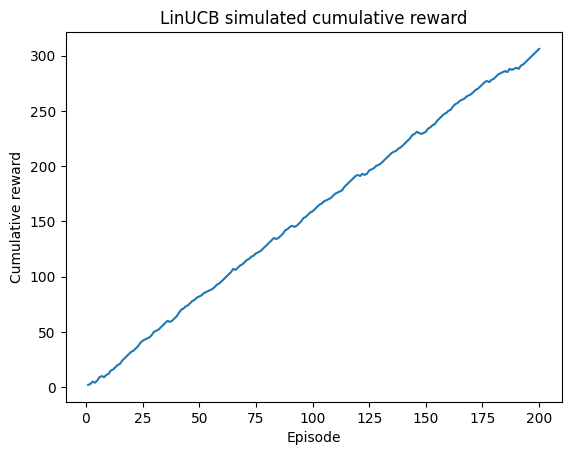

,count
feedback,
complete,70
like,62
replay,36
playlist_added,18
skip,14


In [17]:
def simulate_feedback(user_id, row_idx):
    distance=np.linalg.norm(X_unit[row_idx]-preference_profiles[user_id])/np.sqrt(len(FEATURES))
    p_like=float(np.clip(1/(1+np.exp(-8*(.42-distance))),.05,.95))
    liked=bool(rng.random()<p_like)
    if liked:
        return rng.choice(["like","complete","replay","playlist_added"],p=[.35,.35,.20,.10]).item()
    return "skip"
episode_rows=[]
for episode in range(N_EPISODES):
    pool=hybrid_recommend(demo_user,n=min(50,len(tracks)),exclude_rows=consumed_rows)
    if pool.empty: break
    chosen, diagnostics=linucb_select(demo_user,pool)
    feedback=simulate_feedback(demo_user,chosen); reward=reward_for(feedback); linucb_update(demo_user,chosen,reward)
    consumed_rows.add(chosen)
    episode_rows.append({"episode":episode+1,"track_row":chosen,"feedback":feedback,"reward":reward,**diagnostics})
episode_log=pd.DataFrame(episode_rows)
if not episode_log.empty:
    episode_log["cumulative_reward"]=episode_log.reward.cumsum()
    display(episode_log.tail())
    plt.plot(episode_log.episode,episode_log.cumulative_reward); plt.xlabel("Episode"); plt.ylabel("Cumulative reward"); plt.title("LinUCB simulated cumulative reward"); plt.show()
    display(episode_log.feedback.value_counts().rename("count").to_frame())

## 17. Recommendation Evaluation
**What / why:** Compare Random, Content, Hybrid, and Hybrid+LinUCB on a fresh set of candidate pools using the same probabilistic simulator. Precision/recall/NDCG use simulated binary likes; rates and reward use sampled interaction outcomes. This is a simulator comparison, not a real-user claim.

In [18]:
def ranking_metrics(relevances, k):
    rel=np.asarray(relevances[:k],dtype=int); precision=rel.mean() if len(rel) else 0.0
    total=max(1,int(np.sum(relevances))); recall=float(rel.sum()/total)
    ndcg=float(ndcg_score([relevances], [np.arange(len(relevances),0,-1)], k=k)) if len(relevances) else 0.0
    return precision,recall,ndcg
def evaluate_methods(n_users=5, n_trials=20):
    methods=["Random","Content-based","Hybrid ML","Hybrid ML + LinUCB"]
    records=[]
    for ui,user_id in enumerate(list(preference_profiles)[:n_users]):
        for trial in range(n_trials):
            pool=hybrid_recommend(user_id,n=min(50,len(tracks)))
            pool_rows=pool.catalog_row.to_numpy()
            content_rows= recommend_content(user_id=user_id,n=len(pool)).index.to_numpy() # metadata index maps to catalog row
            rand_rows=rng.choice(pool_rows,size=len(pool_rows),replace=False)
            contexts=list(pool_rows); selected, _=linucb_select(user_id,pool)
            ucb_rows=[selected]+[r for r in contexts if r!=selected]
            rankings={"Random":rand_rows,"Content-based":content_rows,"Hybrid ML":pool_rows,"Hybrid ML + LinUCB":np.asarray(ucb_rows)}
            for method,rows in rankings.items():
                labels=np.array([int(simulate_feedback(user_id,int(r))!="skip") for r in rows])
                p5,r5,n5=ranking_metrics(labels,5); p10,r10,n10=ranking_metrics(labels,10)
                outcomes=[simulate_feedback(user_id,int(r)) for r in rows[:10]]
                rewards=[reward_for(x) for x in outcomes]
                records.append({"method":method,"precision@5":p5,"precision@10":p10,"recall@5":r5,"recall@10":r10,"ndcg@5":n5,"ndcg@10":n10,"like_rate":np.mean([x!="skip" for x in outcomes]),"skip_rate":np.mean([x=="skip" for x in outcomes]),"completion_rate":np.mean([x=="complete" for x in outcomes]),"average_reward":np.mean(rewards)})
    return pd.DataFrame(records).groupby("method").mean(numeric_only=True)
baseline_results=evaluate_methods()
display(baseline_results)

,precision@5,precision@10,recall@5,recall@10,ndcg@5,ndcg@10,like_rate,skip_rate,completion_rate,average_reward
method,,,,,,,,,,
Content-based,0.948,0.948,0.101211,0.202378,0.947774,0.948180,0.941,0.059,0.319,1.603
Hybrid ML,0.938,0.932,0.100988,0.200685,0.936287,0.932828,0.928,0.072,0.349,1.534
Hybrid ML + LinUCB,0.916,0.922,0.099269,0.200055,0.908594,0.915638,0.930,0.070,0.330,1.546
Random,0.924,0.937,0.099391,0.201750,0.921226,0.931069,0.904,0.096,0.316,1.486


## 18. Spotify Integration
**What / why:** Spotify is optional and is only used for catalog search and playback. This implementation uses user OAuth; search requires no playback permission, while device listing and controls request their specific scopes. Spotify track IDs from the CSV are not trusted as matches.

**Platform note (verified 2026-09-25):** New Web API apps have been restricted from Audio Features and Recommendations endpoints since Spotify's 2024 policy changes. Playback control requires Premium and an active Spotify Connect device. Development-mode app requirements and endpoint availability can also change. This notebook uses locally supplied features and only attempts endpoints the configured account/app is allowed to call. [Spotify Web API changes](https://developer.spotify.com/blog/2024-11-27-changes-to-the-web-api), [Playback requirements](https://developer.spotify.com/documentation/web-api/reference/start-a-users-playback), [2026 migration guidance](https://developer.spotify.com/documentation/web-api/tutorials/february-2026-migration-guide). Missing credentials or API access do not stop ML mode.

In [19]:
# Optional dependency: pip install spotipy python-dotenv
SPOTIFY_AUTH_STATUS="Not configured"; spotify_client=None
try:
    from dotenv import load_dotenv
    load_dotenv()
except ImportError:
    print("python-dotenv missing; environment variables can still be set manually.")
SPOTIFY_CLIENT_ID=os.getenv("SPOTIFY_CLIENT_ID")
SPOTIFY_CLIENT_SECRET=os.getenv("SPOTIFY_CLIENT_SECRET")
SPOTIFY_REDIRECT_URI=os.getenv("SPOTIFY_REDIRECT_URI", "http://127.0.0.1:8888/callback")
SPOTIFY_SCOPES="user-read-playback-state user-modify-playback-state"
if SPOTIFY_CLIENT_ID and SPOTIFY_CLIENT_SECRET:
    try:
        import spotipy
        from spotipy.oauth2 import SpotifyOAuth
        spotify_client=spotipy.Spotify(auth_manager=SpotifyOAuth(client_id=SPOTIFY_CLIENT_ID,client_secret=SPOTIFY_CLIENT_SECRET,redirect_uri=SPOTIFY_REDIRECT_URI,scope=SPOTIFY_SCOPES,open_browser=True))
        spotify_client.current_user()
        SPOTIFY_AUTH_STATUS="Authenticated"
    except Exception as e:
        SPOTIFY_AUTH_STATUS=f"Authentication unavailable: {type(e).__name__}: {e}"
else:
    SPOTIFY_AUTH_STATUS="Credentials missing; ML TEST MODE remains available"
print("Spotify status:", SPOTIFY_AUTH_STATUS)

Spotify status: Authenticated


In [20]:
def spotify_search_match(track_name, artist_name, limit=10):
    if spotify_client is None: return {"status":"unavailable", "reason":SPOTIFY_AUTH_STATUS}
    if not track_name or pd.isna(track_name): return {"status":"no track name"}
    query=f'track:"{track_name}"' + (f' artist:"{artist_name}"' if artist_name and not pd.isna(artist_name) else "")
    try:
        items=spotify_client.search(q=query,type="track",limit=limit).get("tracks",{}).get("items",[])
        if not items: return {"status":"no match","query":query}
        from difflib import SequenceMatcher
        def norm(x): return re.sub(r"[^a-z0-9]", "", str(x).lower())
        ranked=[]
        for item in items:
            tn=SequenceMatcher(None,norm(track_name),norm(item["name"])).ratio()
            arts=" ".join(a["name"] for a in item.get("artists",[]))
            an=SequenceMatcher(None,norm(artist_name or ""),norm(arts)).ratio() if artist_name else .5
            ranked.append((.55*tn+.45*an,item))
        confidence,item=max(ranked,key=lambda x:x[0])
        return {"status":"matched","track_id":item["id"],"name":item["name"],"artists":", ".join(a["name"] for a in item.get("artists",[])),"url":item.get("external_urls",{}).get("spotify"),"confidence":confidence,"query":query}
    except Exception as e: return {"status":"search failed","reason":f"{type(e).__name__}: {e}"}
def spotify_devices():
    if spotify_client is None: return {"status":SPOTIFY_AUTH_STATUS}
    try: return spotify_client.devices()
    except Exception as e: return {"status":f"Device lookup unavailable: {type(e).__name__}: {e}"}
def spotify_play(track_id, device_id=None):
    if spotify_client is None: return {"status":SPOTIFY_AUTH_STATUS}
    try:
        spotify_client.start_playback(device_id=device_id,uris=[f"spotify:track:{track_id}"])
        return {"status":"play command accepted"}
    except Exception as e: return {"status":f"Playback unavailable or rejected: {type(e).__name__}: {e}; playback requires Premium and an active compatible device."}
def spotify_pause():
    try: spotify_client.pause_playback(); return {"status":"pause command accepted"}
    except Exception as e: return {"status":f"Pause unavailable: {type(e).__name__}: {e}"}
def spotify_next():
    try: spotify_client.next_track(); return {"status":"next command accepted"}
    except Exception as e: return {"status":f"Next unavailable: {type(e).__name__}: {e}"}
print("Devices:", spotify_devices())

Devices: {'devices': []}


## 19. End-to-End Demo
**What / why:** Select a LinUCB action from a fresh Top-50 pool, optionally search and attempt Spotify playback, then accept manual feedback or use simulated feedback. The feedback reward updates the selected arm for the next recommendation. Leave `MANUAL_FEEDBACK=None` for safe noninteractive use.

In [21]:
USE_INTERACTIVE_FEEDBACK = False  # set True in a live notebook session to enter a response
MANUAL_FEEDBACK = None  # or set 'like', 'complete', 'replay', 'skip', or 'playlist_added'
demo_pool=hybrid_recommend(demo_user,n=min(50,len(tracks)))
display(demo_pool.head(10))
selected_row, selection_info=linucb_select(demo_user,demo_pool)
print("LinUCB selected catalog row", selected_row, "with", selection_info)
name=metadata.iloc[selected_row][TRACK_NAME_COL] if TRACK_NAME_COL else None
artist=metadata.iloc[selected_row][ARTIST_COL] if ARTIST_COL else None
match=spotify_search_match(name,artist)
print("Spotify match:", match)
if match.get("status")=="matched": print("Playback attempt:", spotify_play(match["track_id"]))
if USE_INTERACTIVE_FEEDBACK and MANUAL_FEEDBACK is None:
    MANUAL_FEEDBACK=input("Feedback [like/complete/replay/skip/playlist_added]: ").strip().lower()
if USE_INTERACTIVE_FEEDBACK and MANUAL_FEEDBACK is None:
    MANUAL_FEEDBACK=input("Feedback [like/complete/replay/skip/playlist_added]: ").strip().lower()
feedback=MANUAL_FEEDBACK or simulate_feedback(demo_user,selected_row)
reward=reward_for(feedback); linucb_update(demo_user,selected_row,reward)
print("Feedback:",feedback,"| reward:",reward,"| LinUCB updated")

,year,artists,explicit,id,key,mode,name,popularity,release_date,genres,catalog_row,content_score,predicted_like_probability,hybrid_score
0,1975,['Led Zeppelin'],0,6IBn2H6Axqg4mc4PZW6jRz,7,1,Black Country Woman - Remaster,32,1975-02-24,"album rock, classic rock, hard rock, rock",83358,0.954696,0.888277,0.921486
1,2010,['Kid Cudi'],0,3fV84Z6UdxxHqfGIMmuSKg,1,1,Trapped In My Mind,53,2010-11-09,"hip hop, ohio hip hop, pop rap, rap",55307,0.927688,0.906067,0.916877
2,1982,['Rick Springfield'],0,1syhTK7LlvpeWdZNsZARP0,1,0,Don't Talk to Strangers,53,1982-03-23,"album rock, australian rock, classic rock, dan...",12124,0.942554,0.891182,0.916868
3,1984,['Charly García'],0,2MXqrO1RBfek6RoijghYYp,7,0,Promesas Sobre El Bidet,55,1984-01-01,"argentine rock, latin alternative, latin rock,...",101575,0.943933,0.888225,0.916079
4,1984,['Hot Streak'],0,5gcLUfLPnfi8GMkRSrM2gO,4,0,Body Work,21,1984-01-01,Unknown,163359,0.945387,0.883768,0.914577
5,1976,['ABBA'],0,3lKN03PDeBnXZS7sDukRBt,9,0,"Money, Money, Money",59,1976,"europop, swedish pop",29807,0.943716,0.885137,0.914427
6,2009,['Rojo'],0,6EO3eTy12sRwzgbXZhHpJn,1,1,Te Amo Más Que A Mi Misma Vida,54,2009-03-03,"corrido, nuevo regional mexicano, regional mex...",138655,0.913155,0.914340,0.913747
7,2013,['Los Cuates de Sinaloa'],0,6s2n7VHlMheKsMn2ra6Kt0,5,0,El Señor de los Cielos,48,2013-04-01,"corrido, deep regional mexican, norteno, nuevo...",169100,0.898146,0.929054,0.913600
8,2004,['La Oreja de Van Gogh'],0,06p2Ij0lXD45LODQDCov0u,9,1,Rosas,61,2004-05-10,"latin, latin arena pop, latin pop, mexican pop...",16504,0.916653,0.910204,0.913429
9,1989,['Kino'],0,4BFIJnvxBhlny63mmoK91A,7,1,Последний герой,47,1989-01-01,"classic russian rock, russian chanson, russian...",134620,0.950467,0.876126,0.913297


LinUCB selected catalog row 71622 with {'predicted_reward': 2.6187851765864836, 'exploration_bonus': 0.6540144586901672, 'ucb': 3.272799635276651}


HTTP Error for PUT to https://api.spotify.com/v1/me/player/play with Params: {} returned 404 due to Player command failed: No active device found


Spotify match: {'status': 'matched', 'track_id': '3AR1c3Dssq51WlGGkuYJNj', 'name': 'El lado oscuro', 'artists': 'Jarabe De Palo', 'url': 'https://open.spotify.com/track/3AR1c3Dssq51WlGGkuYJNj', 'confidence': 1.0, 'query': 'track:"El lado oscuro" artist:"[\'Jarabe De Palo\']"'}
Playback attempt: {'status': 'Playback unavailable or rejected: SpotifyException: http status: 404, code: -1 - https://api.spotify.com/v1/me/player/play:\n Player command failed: No active device found, reason: NO_ACTIVE_DEVICE; playback requires Premium and an active compatible device.'}
Feedback: like | reward: 2 | LinUCB updated


## 20. Conclusions and Actual Run Summary
**What / why:** Summarize measured outputs from this execution. A conclusion is produced only after dataset cells have run; no metrics are prefilled.

In [22]:
print("DATASET")
print(f"tracks={len(tracks):,}; source columns={tracks_raw.shape[1]}; model features={FEATURES}")
print("PCA components:", n_components, "| explained variance:", round(float(pca.explained_variance_ratio_.sum()),4))
print("K values tested:", K_VALUES, "| selected:", selected_k, "| silhouette:", round(float(cluster_results.loc[cluster_results.k==selected_k,'silhouette'].iloc[0]),4))
print("SUPERVISED models tested:", model_metrics.model.tolist(), "| selected by held-out F1:", best_model_name)
display(model_metrics)
print("Top 10 hybrid recommendations:"); display(hybrid_recommend(demo_user,n=10))
print("RL episodes completed:",len(episode_log),"| cumulative reward:",int(episode_log.reward.sum()) if len(episode_log) else 0,"| reward config:",REWARDS)
display(baseline_results)
print("Spotify auth:",SPOTIFY_AUTH_STATUS,"| example match:",match,"| playback attempt is reported above only when a Spotify match was found.")

DATASET
tracks=170,653; source columns=19; model features=['valence', 'acousticness', 'danceability', 'duration_ms', 'energy', 'instrumentalness', 'liveness', 'loudness', 'speechiness', 'tempo']
PCA components: 7 | explained variance: 0.9152
K values tested: [2, 3, 4, 5, 6, 7, 8, 9, 10] | selected: 2 | silhouette: 0.24
SUPERVISED models tested: ['Gradient Boosting', 'KNN', 'Random Forest', 'Logistic Regression', 'Decision Tree'] | selected by held-out F1: Gradient Boosting


,model,accuracy,precision,recall,f1,roc_auc
0,Gradient Boosting,0.713147,0.727273,0.939828,0.820000,0.624548
1,KNN,0.685259,0.717540,0.902579,0.799492,0.641600
2,Random Forest,0.657371,0.738544,0.785100,0.761111,0.619623
3,Logistic Regression,0.663347,0.783019,0.713467,0.746627,0.660973
4,Decision Tree,0.631474,0.725275,0.756447,0.740533,0.500478


Top 10 hybrid recommendations:


,year,artists,explicit,id,key,mode,name,popularity,release_date,genres,catalog_row,content_score,predicted_like_probability,hybrid_score
0,1975,['Led Zeppelin'],0,6IBn2H6Axqg4mc4PZW6jRz,7,1,Black Country Woman - Remaster,32,1975-02-24,"album rock, classic rock, hard rock, rock",83358,0.954696,0.888277,0.921486
1,2010,['Kid Cudi'],0,3fV84Z6UdxxHqfGIMmuSKg,1,1,Trapped In My Mind,53,2010-11-09,"hip hop, ohio hip hop, pop rap, rap",55307,0.927688,0.906067,0.916877
2,1982,['Rick Springfield'],0,1syhTK7LlvpeWdZNsZARP0,1,0,Don't Talk to Strangers,53,1982-03-23,"album rock, australian rock, classic rock, dan...",12124,0.942554,0.891182,0.916868
3,1984,['Charly García'],0,2MXqrO1RBfek6RoijghYYp,7,0,Promesas Sobre El Bidet,55,1984-01-01,"argentine rock, latin alternative, latin rock,...",101575,0.943933,0.888225,0.916079
4,1984,['Hot Streak'],0,5gcLUfLPnfi8GMkRSrM2gO,4,0,Body Work,21,1984-01-01,Unknown,163359,0.945387,0.883768,0.914577
5,1976,['ABBA'],0,3lKN03PDeBnXZS7sDukRBt,9,0,"Money, Money, Money",59,1976,"europop, swedish pop",29807,0.943716,0.885137,0.914427
6,2009,['Rojo'],0,6EO3eTy12sRwzgbXZhHpJn,1,1,Te Amo Más Que A Mi Misma Vida,54,2009-03-03,"corrido, nuevo regional mexicano, regional mex...",138655,0.913155,0.914340,0.913747
7,2013,['Los Cuates de Sinaloa'],0,6s2n7VHlMheKsMn2ra6Kt0,5,0,El Señor de los Cielos,48,2013-04-01,"corrido, deep regional mexican, norteno, nuevo...",169100,0.898146,0.929054,0.913600
8,2004,['La Oreja de Van Gogh'],0,06p2Ij0lXD45LODQDCov0u,9,1,Rosas,61,2004-05-10,"latin, latin arena pop, latin pop, mexican pop...",16504,0.916653,0.910204,0.913429
9,1989,['Kino'],0,4BFIJnvxBhlny63mmoK91A,7,1,Последний герой,47,1989-01-01,"classic russian rock, russian chanson, russian...",134620,0.950467,0.876126,0.913297


RL episodes completed: 200 | cumulative reward: 306 | reward config: {'like': 2, 'complete': 1, 'replay': 2, 'skip': -1, 'playlist_added': 3}


,precision@5,precision@10,recall@5,recall@10,ndcg@5,ndcg@10,like_rate,skip_rate,completion_rate,average_reward
method,,,,,,,,,,
Content-based,0.948,0.948,0.101211,0.202378,0.947774,0.948180,0.941,0.059,0.319,1.603
Hybrid ML,0.938,0.932,0.100988,0.200685,0.936287,0.932828,0.928,0.072,0.349,1.534
Hybrid ML + LinUCB,0.916,0.922,0.099269,0.200055,0.908594,0.915638,0.930,0.070,0.330,1.546
Random,0.924,0.937,0.099391,0.201750,0.921226,0.931069,0.904,0.096,0.316,1.486


Spotify auth: Authenticated | example match: {'status': 'matched', 'track_id': '3AR1c3Dssq51WlGGkuYJNj', 'name': 'El lado oscuro', 'artists': 'Jarabe De Palo', 'url': 'https://open.spotify.com/track/3AR1c3Dssq51WlGGkuYJNj', 'confidence': 1.0, 'query': 'track:"El lado oscuro" artist:"[\'Jarabe De Palo\']"'} | playback attempt is reported above only when a Spotify match was found.


In [23]:
# Save lightweight artifacts from the actual run.
joblib.dump({"imputer":imputer,"scaler":scaler,"pca":pca,"kmeans":kmeans,"supervised_model":best_model,"features":FEATURES,"metadata":metadata,"X_scaled":X_scaled,"linucb_A":linucb_A,"linucb_b":linucb_b,"linucb_alpha":LINUCB_ALPHA}, MODEL_DIR/"tunetwin_testing_artifacts.joblib")
print("Saved models/tunetwin_testing_artifacts.joblib")

Saved models/tunetwin_testing_artifacts.joblib


### Future Development

Notebook
   ↓
Reusable Python modules
   ↓
FastAPI backend
   ↓
React frontend
   ↓
Spotify playback layer

This is intentionally outside the current prototype.